# Gaussian mocks for the desilike fits: detection p-values, error calibration, difference p-values

**What it does.** Three tests of the desilike fits of `desilike_fits.ipynb`, all with the same kind of mock:
a model monopole chosen by us plus a random draw of the noise from the covariance,

$$
\boxed{\;\hat\xi_0^{\,\rm mock}=\mathbf m_{\rm in}+\mathsf L\,\mathbf z\;}
$$

where $\mathbf m_{\rm in}$ is the model ξ₀ in the fit bins at the input ("true") parameters, $\mathsf C=\mathsf L\mathsf L^{\rm T}$ is the
covariance of the fit (its Cholesky factor $\mathsf L$), and $\mathbf z$ is a vector of independent standard Gaussian numbers.
Each mock is then fitted exactly as the real data (same functions, same settings). Since the input is known,
the fits of many mocks show how the fitting method behaves at our noise level. The mocks are drawn from the
covariance, so they test the fits and their error bars, not the covariance itself
(`notebooks/exploratory/gaussian_covariance_checks/`).

1. **Detection p-value (per sample).** Input: the best fit of the no-wiggle model (no BAO) to the sample. Each
   mock gets the α fit and the no-wiggle fit, giving Δχ²_det as for the data. The p-value is the fraction of
   mocks whose Δχ²_det is at least the data's: how often a sample *without* BAO looks as BAO-like as ours.
2. **Error calibration (per sample, α and Σ).** Input: the best fit of the α fit (Gaussian Σ prior) to the sample,
   $\alpha_{\rm in}$ and $\Sigma_{\rm in}$. Each mock gets the α fit with its 68% interval and the Σ fit with its profile interval, as for
   the data. For α, the pull of mock $i$,
   $$
   {\rm pull}_i=\frac{\hat\alpha_i-\alpha_{\rm in}}{\sigma_{\alpha,i}},
   $$
   with $\hat\alpha_i$ its best fit and $\sigma_{\alpha,i}$ the half-width of its 68% interval: honest errors give pulls with mean 0
   and standard deviation 1 ("pull std"). The coverage is the fraction of mocks whose 68% interval contains the
   input value: 0.68 for honest intervals. For Σ only the coverage is computed, because its intervals are often
   one-sided (they stop at Σ = 0), and the fraction of mocks whose best-fit Σ falls below `Sigma_low` is listed.
3. **Difference p-values (per pair, Δα and ΔΣ).** For a pair (A, B) of `pairs` and one parameter θ (α or Σ),
   the statistic is the one of the section 7 tables of `desilike_fits.ipynb`,
   $$
   \Delta\chi^2(0)=\chi^2_{\min}(\Delta\theta=0)-\chi^2_{\min},
   $$
   the increase of the joint χ² of the two samples when they are forced to share θ ($\chi^2_{\min}$: with $\Delta\theta=\theta_A-\theta_B$
   free). The null hypothesis is "no difference": the input of the mocks is the joint fit **with** $\Delta\theta=0$ (each
   sample keeps its own other parameters), i.e. the data's best description if there is no difference. The noise
   is drawn from the joint covariance of the two samples (cross block included). The p-value is the fraction of
   mocks with Δχ²(0) at least the data's. With `null_theory_check`, the same is repeated with a second input:
   both samples at α = 1 and Σ = Σ_th (each with its own amplitude and broadband refitted there), to see whether
   the p-value depends on where the null is placed.

A p-value of k/N means k of the N mocks reached the data's value; with k = 0 it is only bounded, p < 1/N.
The mocks of each sample, test and pair are saved in `MOCK_DIR` (file name = test, sample(s) and settings) and
reloaded on the next run unless `recompute = True`, so an interrupted run continues where it stopped.
All numbers are in the cell outputs.

In [1]:
import os, sys, warnings, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf

from cosmoprimo.fiducial import Cosmology
from desilike.theories.galaxy_clustering import (BAOPowerSpectrumTemplate,
                                                 DampedBAOWigglesTracerCorrelationFunctionMultipoles)
from desilike.observables.galaxy_clustering import TracerCorrelationFunctionMultipolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.profilers import MinuitProfiler
from iminuit import Minuit

import zlib
from scipy import stats
DESI, DATA, FREE = '#eb6834', '0.15', '#2a78d6'   # as in desilike_fits: alpha fit, data, Sigma-free fit
SCOL = {'Full': '0.15', 'Fil': '#6250d6', 'NonFil': '#1baf7a', 'Full dil nFil': '#eda100', 'Full dil nNonFil': '#e87ba4'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---------------- settings (change here only) ----------------
mag = -20.8                         # absolute-magnitude cut of the run (part of the file names)
binsep = 2.5                        # bin width of the monopoles [h^-1 Mpc]
mono_sep = (5.0, 200.0)             # separation range of the monopole files [h^-1 Mpc] (in their names)
split_name = 'dist_fil'             # split variable(s) of the run (in the spectra file name)
fit_range = (50., 150.)             # [h^-1 Mpc]
Sigma_prior_sd = 6.0                # width of the Gaussian Sigma prior of the alpha fit (centred on Sigma_th)
Sigma_free = (0., 16.)              # flat prior of the Sigma fit
Sigma_step = 0.5                    # [h^-1 Mpc] grid step of the profile chi2(Sigma)
# differences between samples (section 4): Delta = A - B for each (A, B)
pairs = [('Fil', 'Full dil nFil'), ('NonFil', 'Full dil nNonFil'), ('Fil', 'NonFil'), ('Fil', 'Full'), ('NonFil', 'Full')]
# mocks
n_mock = 50                        # mocks per sample and test, and per pair and parameter
seed = 1                            # random seed (each sample / pair / test gets its own stream from it)
Sigma_low = 1.0                     # [h^-1 Mpc] calibration: fraction of mocks with best-fit Sigma below this
null_theory_check = True            # differences: also the null at alpha = 1, Sigma = Sigma_th (doubles that time)
recompute = False                   # True: refit the mocks even if saved results exist

# sample -> <bin_desc> of the monopole files (= label in the spectra file); the random dilutions of Full
# are added per configuration from its spectra file (their label contains N)
base_samples = {'Full': 'full',
                'Fil': '0.0leqd_mathrmfilleq3.0',
                'NonFil': '10.0leqd_mathrmfilleq100.0'}
dilution_of = ('Fil', 'NonFil')     # add 'Full dil n<sample>' for these samples, if in the spectra file
plot_samples = ['Full', 'Fil', 'NonFil']      # the dilutions appear in tables and in the parameter figures only
# -------------------------------------------------------------
MONO = os.path.join(REPO, 'data/processed/monopoles/box')
MOCK_DIR = os.path.join(REPO, 'data/processed/mocks/desilike')
os.makedirs(MOCK_DIR, exist_ok=True)
# settings that change the fits: part of the names of the saved mock files
tag = (f"mag{mag:.1f}_sep{mono_sep[0]:g}-{mono_sep[1]:g}_bin{binsep:g}_fit{fit_range[0]:g}-{fit_range[1]:g}_"
       f"Sprior{Sigma_prior_sd:g}_Sfree{Sigma_free[0]:g}-{Sigma_free[1]:g}_n{n_mock}_seed{seed}")

def monopole_file(mag, binsep, key):
    # file written by multidark_analysis.py; None if missing.  Older files (e.g. mag -21.2 at bin width 2.5)
    # carry the label with '-d' in place of 'leqd': same sample, same N (where a file exists under both
    # names the two monopoles are identical).  The label in the spectra file is always the 'leqd' one.
    for lab_ in (key, key.replace('leqd', '-d')):
        f = os.path.join(MONO, f'mag={mag:.1f}_sep={mono_sep[0]:.1f}-{mono_sep[1]:.1f}_binsep={binsep:.1f}_{lab_}.npz')
        if os.path.exists(f):
            return f
    return None

C0 = bf.COSMO
cosmo = Cosmology(h=C0['H0'] / 100., omega_b=C0['ombh2'], omega_cdm=C0['omch2'], A_s=C0['As'], n_s=C0['ns'],
                  m_ncdm=[] if C0.get('mnu', 0.06) == 0 else [C0['mnu']], engine='camb')
lin = bf.linear_theory()
k, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k, P_w, P_nw, lin)
Sigma_th = bf.sigma_nl_theory(lin)['Sigma_mono']

print(f"magnitude cut {mag};  bin width {binsep} h^-1 Mpc;  fit range {fit_range} h^-1 Mpc;  monopole files cover {mono_sep}")
print(f"alpha fit: Sigma ~ N({Sigma_th:.2f}, {Sigma_prior_sd:g}) [Sigma_th = Zel'dovich prediction];  "
      f"Sigma fit: flat {Sigma_free}, profile chi2(Sigma) in steps of {Sigma_step:g}")
print("covariance: bf.gaussian_cov_pk with its default settings (as in desilike_fits), from each configuration's spectra file")
print("differences (A - B): " + ", ".join(f"{a} - {b}" for a, b in pairs))
print(f"{n_mock} mocks per sample / pair and test, seed {seed};  theory-null check: {null_theory_check};  "
      f"saved in {os.path.relpath(MOCK_DIR, REPO)} as *_{tag}.npz")

magnitude cut -20.8;  bin width 2.5 h^-1 Mpc;  fit range (50.0, 150.0) h^-1 Mpc;  monopole files cover (5.0, 200.0)
alpha fit: Sigma ~ N(7.78, 6) [Sigma_th = Zel'dovich prediction];  Sigma fit: flat (0.0, 16.0), profile chi2(Sigma) in steps of 0.5
covariance: bf.gaussian_cov_pk with its default settings (as in desilike_fits), from each configuration's spectra file
differences (A - B): Fil - Full dil nFil, NonFil - Full dil nNonFil, Fil - NonFil, Fil - Full, NonFil - Full
50 mocks per sample / pair and test, seed 1;  theory-null check: True;  saved in data/processed/mocks/desilike as *_mag-20.8_sep5-200_bin2.5_fit50-150_Sprior6_Sfree0-16_n50_seed1.npz


## 1. Data, covariance and the fits of the data

The data, covariances and fits of `desilike_fits.ipynb` (sections 1 and 2), with the same functions: for each
sample the α fit (Gaussian Σ prior), the Σ fit (flat prior, with its profile χ²(Σ)) and the no-wiggle fit.
Their best fits are the inputs of the mocks, and their results the values the mocks are compared with.

In [2]:
def load_config(c):
    # monopoles, spectra, covariance bias and covariance of every sample of one configuration
    # (desilike_fits, section 1); returns c with spec, samples and data added
    mag, binsep = c['mag'], c['binsep']
    pk_file = os.path.join(REPO, f'data/processed/pk/box/pk_XISMU_box_mag{mag:.1f}_{split_name}.npz')
    spec = bf.load_spectra(pk_file)
    samples = dict(base_samples)
    for lab in dilution_of:
        n = spec['n_gal'][spec['labels'].index(samples[lab])]
        dil = [l for l, nn in zip(spec['labels'], spec['n_gal']) if l.startswith('FullrandomN-') and nn == n]
        if dil:
            samples[f'Full dil n{lab}'] = dil[0]
    data = {}
    for lab, key in samples.items():
        f = monopole_file(mag, binsep, key)
        if f is None:
            print(f"SKIP {lab}: no monopole file for label '{key}' at bin width {binsep} "
                  f"(run scripts/multidark_analysis.py with mag_max = {mag}, bin_size_2d = {binsep})")
            continue
        s, xi, n_gal = bf.load_monopole(f)
        edges = bf.edges_from_centres(s)
        assert edges[0] <= fit_range[0] and edges[-1] >= fit_range[1], \
            f"{lab}: monopole covers {edges[0]}-{edges[-1]}, fit_range is {fit_range}"
        i_spec = spec['labels'].index(key)
        assert int(spec['n_gal'][i_spec]) == n_gal, f"{lab}: N differs from the spectra file"
        b = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)['b']
        C = bf.gaussian_cov_pk(edges, spec, [i_spec], [b], lin)
        m = (s >= fit_range[0]) & (s <= fit_range[1])
        data[lab] = dict(s=s, xi=xi, edges=edges, C=C, sig=np.sqrt(np.diag(C)), m=m, n_gal=n_gal, b=b,
                         binsep=binsep, file=os.path.basename(f))
        print(f"{lab:<18} N = {n_gal:>8d}   {m.sum():>2d} bins in fit range   b(cov) = {b:.3f}   {os.path.basename(f)}")
    return dict(c, spec=spec, pk_file=pk_file, samples=samples, data=data)

C = load_config(dict(mag=mag, binsep=binsep))
spec, samples, data = C['spec'], C['samples'], C['data']
print(f"spectra file: {os.path.basename(C['pk_file'])}")
labs = [l for l in ('Full', 'Fil', 'Full dil nFil', 'NonFil', 'Full dil nNonFil') if l in data]

def desilike_theory(prior='gauss', only_now=False):
    # the BAO model of all fits (one sample); returns the theory and its template
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power')
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True)
    P['sigmas'].update(value=0., fixed=True)
    if prior == 'gauss':
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(dist='norm', loc=Sigma_th, scale=Sigma_prior_sd, limits=[0., 30.]))
    else:
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(limits=list(Sigma_free)))
    P['sigmapar'].update(derived='{sigmaper}')
    for name in ('al0_1', 'al0_2'):
        P[name].update(value=0., fixed=True)
    if only_now:
        P['sigmaper'].update(fixed=True, value=Sigma_th, prior=None)
        tpl.init.params['qiso'].update(fixed=True, value=1.)
    return th, tpl

def desilike_lik(d, prior='gauss', only_now=False):
    th, _ = desilike_theory(prior, only_now)
    m = d['m']
    obs = TracerCorrelationFunctionMultipolesObservable(
        data=d['xi'][m], s=d['s'][m], covariance=d['C'][np.ix_(m, m)],
        slim={0: (fit_range[0], fit_range[1], d['binsep'])}, wmatrix={'resolution': 10}, theory=th)
    return ObservablesGaussianLikelihood(observables=[obs]), obs

def desilike_fit(lik, interval=False):
    prof = MinuitProfiler(lik, seed=42)
    prof.maximize(niterations=5)
    b = prof.profiles.bestfit
    i = int(np.argmax(b.logposterior))
    pars = {p.name: float(b[p.name][i]) for p in lik.varied_params}
    out = dict(prof=prof, pars=pars, chi2=-2 * float(b['loglikelihood'][i]))
    if interval:
        prof.interval(params=['qiso'])
        iv = prof.profiles.interval['qiso']
        lo, hi = pars['qiso'] + iv[0], pars['qiso'] + iv[1]
        # desilike stops the interval at the prior edges (0.8, 1.2): report that as open
        out['lo'] = np.nan if lo <= 0.8 + 1e-3 else lo
        out['hi'] = np.nan if hi >= 1.2 - 1e-3 else hi
    return out

def interval_68(x, dchi2):
    # Delta chi2 = 1 interval around the minimum of a profile, crossings interpolated linearly between
    # grid points; nan on a side where Delta chi2 stays below 1 up to the end of the grid
    i0 = int(np.argmin(dchi2))
    up = [i for i in range(i0, len(x)) if dchi2[i] > 1]
    dn = [i for i in range(i0, -1, -1) if dchi2[i] > 1]
    hi = np.interp(1., dchi2[[up[0] - 1, up[0]]], x[[up[0] - 1, up[0]]]) if up else np.nan
    lo = np.interp(1., dchi2[[dn[0] + 1, dn[0]]], x[[dn[0] + 1, dn[0]]]) if dn else np.nan
    return lo, hi

def sigma_profile(lik, Sigma_best):
    # Delta chi2(Sigma) on a grid over Sigma_free (all other varied parameters refitted at each point), its
    # Delta chi2 = 1 interval and its value at Sigma_th.  lo / hi = nan: the interval reaches the edge of Sigma_free.
    grid = np.union1d(np.arange(Sigma_free[0], Sigma_free[1] + 1e-9, Sigma_step), [Sigma_th, Sigma_best])
    prof = MinuitProfiler(lik, seed=42)
    prof.profile(params=['sigmaper'], grid=grid)
    pr = np.asarray(prof.profiles.profile['sigmaper'])
    S, dchi2 = pr[:, 0], -2 * (pr[:, 1] - pr[:, 1].max())     # flat prior: log-posterior = log-likelihood + const
    lo, hi = interval_68(S, dchi2)
    return dict(S=S, dchi2=dchi2, lo=lo, hi=hi, dchi2_th=float(dchi2[np.argmin(np.abs(S - Sigma_th))]))

def fit_config(C):
    # the three fits and the Sigma profile of every sample of one configuration (desilike_fits, section 2)
    res = {}
    t0 = time.time()
    for lab, d in C['data'].items():
        lik_a, obs_a = desilike_lik(d, 'gauss'); f_a = desilike_fit(lik_a, interval=True)
        lik_S, obs_S = desilike_lik(d, 'flat');  f_S = desilike_fit(lik_S, interval=True)
        lik_n, _ = desilike_lik(d, only_now=True); f_n = desilike_fit(lik_n)
        lik_a(**f_a['pars']); model = np.array(obs_a.flattheory)
        lik_S(**f_S['pars']); model_S = np.array(obs_S.flattheory)
        chi2 = f_a['chi2'] + ((f_a['pars']['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2
        n_par = len(lik_a.varied_params)
        prof_Sig = sigma_profile(lik_S, f_S['pars']['sigmaper'])
        res[lab] = dict(fit=f_a, fit_S=f_S, fit_nw=f_n, lik_a=lik_a, lik_S=lik_S, model=model, model_S=model_S,
                        chi2=chi2, det=f_n['chi2'] - chi2, dof=int(d['m'].sum()) + 1 - n_par, prof_Sig=prof_Sig,
                        dof_S=int(d['m'].sum()) - len(lik_S.varied_params), n_par=n_par)
        print(f"{lab:<18} alpha = {f_a['pars']['qiso']:.4f}   alpha (Sigma free) = {f_S['pars']['qiso']:.4f} "
              f"at Sigma = {f_S['pars']['sigmaper']:.2f}   dchi2(Sigma_th) = {prof_Sig['dchi2_th']:.2f}   "
              f"({time.time() - t0:.0f} s)")
    return res

res = fit_config(C)
lik0 = res[labs[0]]['lik_a']
print(f"parameters varied in the alpha fit (N_par = {len(lik0.varied_params)}): {[p.name for p in lik0.varied_params]}")

# ---- tools shared by the three tests ----
def model_vector(lik, obs, pars):
    # model xi_0 in the fit bins at the parameters pars (a dict of the likelihood's varied parameters)
    lik(**pars)
    return np.array(obs.flattheory)

def with_xi(d, xi_fit):
    # copy of the sample's data with xi_0 replaced by xi_fit in the fit bins (a mock)
    xi = d['xi'].copy(); xi[d['m']] = xi_fit
    return dict(d, xi=xi)

def rng_for(name):
    # reproducible random stream for one block of mocks (seed + the block's name)
    return np.random.default_rng([seed, zlib.crc32(name.encode())])

def cached(name, compute):
    # results of one block of mocks: loaded from MOCK_DIR if saved (and recompute is False), else computed and saved
    f = os.path.join(MOCK_DIR, f"{name.replace(' ', '_')}_{tag}.npz")
    if os.path.exists(f) and not recompute:
        return dict(np.load(f))
    t0 = time.time()
    out = compute(rng_for(name))
    np.savez(f, **out)
    print(f"  {name}: {n_mock} mocks in {time.time() - t0:.0f} s, saved")
    return out

def p_value(mock, obs):
    # fraction of mocks at least as large as the data, and the count; mocks with a failed fit (nan) left out
    ok = np.isfinite(mock)
    k = int(np.sum(mock[ok] >= obs))
    return k / ok.sum(), k, int(ok.sum())

def fmt_p(p, k, n):
    return f"< {1 / n:.3f} (0/{n})" if k == 0 else f"{p:.3f} ({k}/{n})"

def chi2_alpha_fit(f):
    # chi2 of the alpha fit with its Gaussian Sigma prior term (as Delta chi2_det of desilike_fits)
    return f['chi2'] + ((f['pars']['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2

Full               N =  4999875   40 bins in fit range   b(cov) = 0.978   mag=-20.8_sep=5.0-200.0_binsep=2.5_full.npz
Fil                N =  1043082   40 bins in fit range   b(cov) = 1.384   mag=-20.8_sep=5.0-200.0_binsep=2.5_0.0leqd_mathrmfilleq3.0.npz
WARNING bias estimate unstable across ranges: (30, 60): 0.607, (40, 70): 0.722, (35, 75): 0.674  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
NonFil             N =  2176035   40 bins in fit range   b(cov) = 0.722   mag=-20.8_sep=5.0-200.0_binsep=2.5_10.0leqd_mathrmfilleq100.0.npz
Full dil nFil      N =  1043082   40 bins in fit range   b(cov) = 0.961   mag=-20.8_sep=5.0-200.0_binsep=2.5_FullrandomN-1043082r20261016.npz
Full dil nNonFil   N =  2176035   40 bins in fit range   b(cov) = 0.967   mag=-20.8_sep=5.0-200.0_binsep=2.5_FullrandomN-2176035r20261016.npz
spectra file: pk_XISMU_box_mag-20.8_dist_fil.npz
Full               alpha = 0.9760   alpha (Sigma free) = 0.9755 at Sigma =

## 2. Detection p-value

Input of the mocks: the best no-wiggle model of each sample. For each mock, the α fit and the no-wiggle fit
give $\Delta\chi^2_{\rm det}=\chi^2(\text{no-wiggle})-\chi^2(\alpha\text{ fit, prior term included})$, exactly as for the data, and

$$
\boxed{\;p_{\rm det}=\frac{\#\{\text{mocks with }\Delta\chi^2_{\rm det}\ge\Delta\chi^2_{\rm det}(\text{data})\}}{N}\;}
$$

with $N$ the number of mocks. The table also lists the median of $\Delta\chi^2_{\rm det}$ over the mocks, its typical value when
there is no BAO. It can be negative: the model of the α fit always contains the BAO feature (its amplitude is
not a free parameter of its own) and pays the Σ prior term, so on data without BAO it can fit worse than the
no-wiggle model. The figure shows the distribution of the mocks, with the data as a vertical line.

  det Full: 50 mocks in 359 s, saved
  det Fil: 50 mocks in 398 s, saved
  det Full dil nFil: 50 mocks in 372 s, saved
  det NonFil: 50 mocks in 422 s, saved
  det Full dil nNonFil: 50 mocks in 368 s, saved
sample            | dchi2_det data | median dchi2_det mocks | p_det           
--------------------------------------------------------------------------------
Full              |          15.30 |                   0.49 | < 0.020 (0/50)  
Fil               |           8.53 |                   1.05 | 0.020 (1/50)    
Full dil nFil     |           8.93 |                  -0.42 | < 0.020 (0/50)  
NonFil            |           1.64 |                   0.95 | 0.300 (15/50)   
Full dil nNonFil  |          11.50 |                  -0.46 | 0.020 (1/50)    


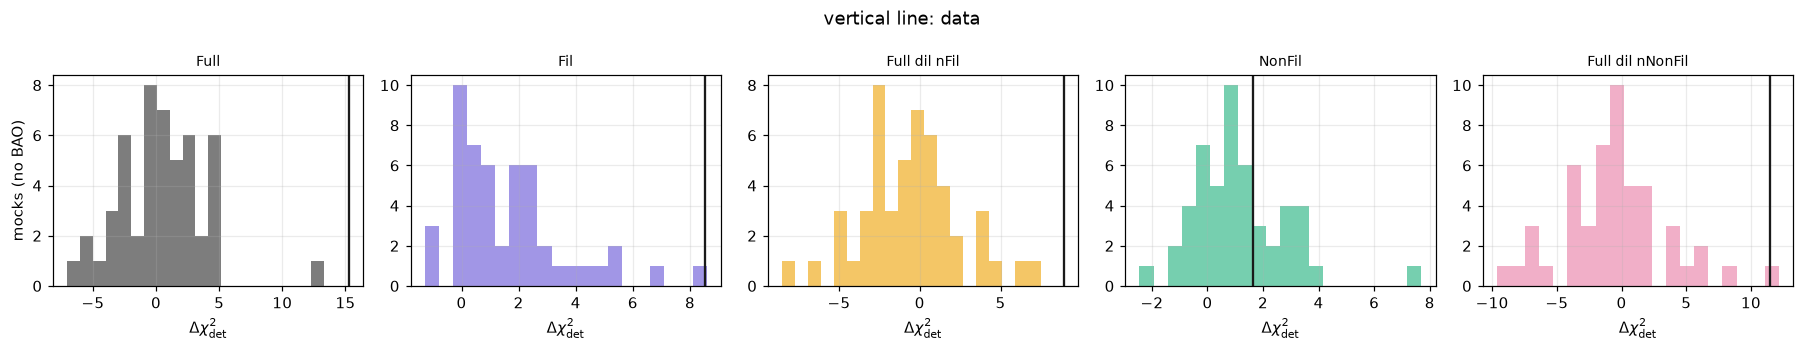

In [3]:
def detection_mocks(lab):
    d, r = data[lab], res[lab]
    lik_n, obs_n = desilike_lik(d, only_now=True)
    m_in = model_vector(lik_n, obs_n, r['fit_nw']['pars'])              # best no-wiggle model of the data
    L = np.linalg.cholesky(d['C'][np.ix_(d['m'], d['m'])])
    def compute(rng):
        det = np.full(n_mock, np.nan)
        for i in range(n_mock):
            dm = with_xi(d, m_in + L @ rng.standard_normal(len(m_in)))
            f_a = desilike_fit(desilike_lik(dm, 'gauss')[0])
            f_n = desilike_fit(desilike_lik(dm, only_now=True)[0])
            det[i] = f_n['chi2'] - chi2_alpha_fit(f_a)
        return dict(det=det)
    return cached(f'det {lab}', compute)

det_mocks = {lab: detection_mocks(lab) for lab in labs}

print(f"{'sample':<18}| {'dchi2_det data':>14} | {'median dchi2_det mocks':>22} | {'p_det':<16}")
print('-' * 80)
for lab in labs:
    dm, dobs = det_mocks[lab]['det'], res[lab]['det']
    print(f"{lab:<18}| {dobs:>14.2f} | {np.nanmedian(dm):>22.2f} | {fmt_p(*p_value(dm, dobs)):<16}")

fig, axes = plt.subplots(1, len(labs), figsize=(3.3 * len(labs), 3.2), squeeze=False)
for ax, lab in zip(axes[0], labs):
    dm = det_mocks[lab]['det']
    ax.hist(dm[np.isfinite(dm)], bins=20, color=SCOL[lab], alpha=0.6)
    ax.axvline(res[lab]['det'], color='0.1', lw=1.5)
    ax.set_title(lab, fontsize=9); ax.set_xlabel(r'$\Delta\chi^2_{\rm det}$')
axes[0, 0].set_ylabel('mocks (no BAO)')
fig.suptitle('vertical line: data'); fig.tight_layout(); plt.show()

## 3. Error calibration: pull std and coverage

Input of the mocks: the best fit of the α fit of each sample ($\alpha_{\rm in}$, $\Sigma_{\rm in}$, its amplitude and broadband). Each mock
gets the α fit with its 68% interval (as for the data) and the Σ fit with its profile interval (`sigma_profile`, as
for the data). Per sample:

* **α:** the bias, mean of $\hat\alpha_i-\alpha_{\rm in}$; the scatter of $\hat\alpha_i$ over the mocks next to the median half-width of the
  intervals (the error the fit reports; the two agree for honest errors); the mean and standard deviation of the
  pulls (0 and 1 for honest errors), from the mocks whose interval is closed; the coverage of the 68% interval
  (an `open` side counts as reaching the α prior edge, 0.8 or 1.2); the fraction of mocks with an open interval.
* **Σ:** the coverage of the 68% interval (an `edge` side counts as reaching the end of `Sigma_free`) and the
  fraction of mocks whose best-fit Σ is below `Sigma_low`.

With $N$ mocks the coverage is known to about $\sqrt{0.68\cdot0.32/N}$. The figure shows the pulls of α (with a
standard Gaussian, the expectation for honest errors) and the best-fit Σ of the mocks (with $\Sigma_{\rm in}$).

In [4]:
def calibration_mocks(lab):
    d, r = data[lab], res[lab]
    m_in = r['model']                                                   # best model of the alpha fit
    L = np.linalg.cholesky(d['C'][np.ix_(d['m'], d['m'])])
    def compute(rng):
        out = {k: np.full(n_mock, np.nan) for k in ('a', 'a_lo', 'a_hi', 'S', 'S_lo', 'S_hi')}
        for i in range(n_mock):
            dm = with_xi(d, m_in + L @ rng.standard_normal(len(m_in)))
            f_a = desilike_fit(desilike_lik(dm, 'gauss')[0], interval=True)
            lik_S = desilike_lik(dm, 'flat')[0]
            f_S = desilike_fit(lik_S)
            pS = sigma_profile(lik_S, f_S['pars']['sigmaper'])
            out['a'][i], out['a_lo'][i], out['a_hi'][i] = f_a['pars']['qiso'], f_a['lo'], f_a['hi']
            out['S'][i], out['S_lo'][i], out['S_hi'][i] = f_S['pars']['sigmaper'], pS['lo'], pS['hi']
        return out
    return cached(f'cal {lab}', compute)

cal_mocks = {lab: calibration_mocks(lab) for lab in labs}

hdr = (f"{'sample':<18}| {'alpha_in':>8} | {'bias':>8} | {'scatter':>7} | {'median err':>10} | {'pull mean':>9} | "
       f"{'pull std':>8} | {'coverage':>8} | {'open':>5} || {'Sigma_in':>8} | {'coverage':>8} | {'Sigma<' + format(Sigma_low, 'g'):>9}")
print(f"{n_mock} mocks per sample;  coverage known to +-{np.sqrt(0.68 * 0.32 / n_mock):.3f}")
print(hdr); print('-' * len(hdr))
pulls = {}
for lab in labs:
    cm, f = cal_mocks[lab], res[lab]['fit']['pars']
    a_in, S_in = f['qiso'], f['sigmaper']
    closed = np.isfinite(cm['a_lo']) & np.isfinite(cm['a_hi'])
    hw = 0.5 * (cm['a_hi'] - cm['a_lo'])
    pulls[lab] = ((cm['a'] - a_in) / hw)[closed]
    lo, hi = np.nan_to_num(cm['a_lo'], nan=0.8), np.nan_to_num(cm['a_hi'], nan=1.2)       # open side = prior edge
    Slo, Shi = np.nan_to_num(cm['S_lo'], nan=Sigma_free[0]), np.nan_to_num(cm['S_hi'], nan=Sigma_free[1])
    ok = np.isfinite(cm['a']); okS = np.isfinite(cm['S'])
    print(f"{lab:<18}| {a_in:>8.4f} | {np.mean(cm['a'][ok] - a_in):>+8.4f} | {np.std(cm['a'][ok]):>7.4f} | "
          f"{np.median(hw[closed]):>10.4f} | {np.mean(pulls[lab]):>+9.2f} | {np.std(pulls[lab]):>8.2f} | "
          f"{np.mean(((lo <= a_in) & (a_in <= hi))[ok]):>8.2f} | {np.mean(~closed[ok]):>5.2f} || "
          f"{S_in:>8.2f} | {np.mean(((Slo <= S_in) & (S_in <= Shi))[okS]):>8.2f} | {np.mean(cm['S'][okS] < Sigma_low):>9.2f}")

fig, axes = plt.subplots(2, len(labs), figsize=(3.3 * len(labs), 6), squeeze=False)
x = np.linspace(-4, 4, 200)
for j, lab in enumerate(labs):
    a0, a1 = axes[0, j], axes[1, j]
    a0.hist(np.clip(pulls[lab], -4, 4), bins=np.linspace(-4, 4, 17), density=True, color=SCOL[lab], alpha=0.6)
    a0.plot(x, stats.norm.pdf(x), color='0.2', lw=1)
    a0.set_title(lab, fontsize=9); a0.set_xlabel(r'pull of $\alpha$')
    S = cal_mocks[lab]['S']
    a1.hist(S[np.isfinite(S)], bins=np.linspace(*Sigma_free, 17), color=SCOL[lab], alpha=0.6)
    a1.axvline(res[lab]['fit']['pars']['sigmaper'], color='0.1', lw=1.5)
    a1.set_xlabel(r'best-fit $\Sigma$ of the mocks [$h^{-1}$Mpc]')
axes[0, 0].set_ylabel('density (curve: standard Gaussian)'); axes[1, 0].set_ylabel(r'mocks (line: $\Sigma_{\rm in}$)')
fig.tight_layout(); plt.show()


Traceback (most recent call last):
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/desilike/profilers/base.py", line 937, in _grid
    profile = Profiles.concatenate(tm_iter.allreduce(list_profiles))
                                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/desilike/utils.py", line 1148, in allreduce
    return self.basecomm.bcast(self.reduce(li), root=0)
                               ^^^^^^^^^^^^^^^
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/desilike/utils.py", line 1144, in reduce
    return self.rootcomm.reduce(li, root=root)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "src/mpi4py/MPI.src/Comm.pyx", line 2173, in mpi4py.MPI.Comm.reduce
  File "src/mpi4py/MPI.src/msgpickle.pxi", line 1347, in mpi4py.MPI.PyMPI_reduce
  File "src/mpi4py/MPI.src/msgpickle.pxi", line 1278, in mpi4py.MPI.PyMPI_reduce_intra
  File "src/mpi4py/MPI.

Exception: Other MPI error, error stack:
internal_Comm_dup(98)...............: MPI_Comm_dup(comm=0xc40013f5, newcomm=0x5b326f5795a0) failed
MPIR_Comm_dup_impl(479).............: 
MPII_Comm_dup(871)..................: 
MPII_Comm_copy(912).................: 
MPIR_Get_contextid_sparse_group(567): Too many communicators (0/2048 free on this process; ignore_id=0)

## 4. Difference p-values: Δα and ΔΣ

For each pair (A, B) in `pairs` and each parameter θ (α, then Σ), the joint fit of the two samples of
`desilike_fits.ipynb`, section 7 (same function `joint_setup`, with the same priors: the Gaussian Σ priors for the
Δα test, the flat prior `Sigma_free` for the ΔΣ test). From the data:

$$
\boxed{\;\Delta\chi^2(0)=\chi^2_{\min}(\Delta\theta=0)-\chi^2_{\min}\;}
$$

computed with two joint fits, Δθ free and Δθ fixed to 0 (the section 7 tables read the same quantity off the
profile grid). The best fit with Δθ = 0 is the input of the null mocks: each mock is that pair of models plus a
draw of the noise from the joint covariance $\mathsf C$ of A and B (fit bins of both, cross block included), and it
gets the same two joint fits, so

$$
p=\frac{\#\{\text{mocks with }\Delta\chi^2(0)\ge\Delta\chi^2(0)(\text{data})\}}{N}.
$$

The table also lists the scatter of the best-fit Δθ over the null mocks: the error of the difference when there
is no difference, next to the measured Δθ. With `null_theory_check`, a second p-value with the null at α = 1,
Σ = Σ_th for both samples (their amplitude and broadband refitted to the data there, `nuisance_fit`).

The figure shows the distribution of Δχ²(0) in the null mocks for each pair (top: Δα, bottom: ΔΣ), with the data
as a vertical line and the χ² distribution with one degree of freedom (grey curve), the distribution expected if
the likelihood were Gaussian: where the histogram follows the curve, √Δχ²(0) can be read as a number of σ.

In [ ]:
def joint_setup(A, B, tie):
    # joint chi2 of samples A and B for tie = 'alpha' (alpha_B = alpha_A - Delta, Gaussian Sigma priors of the alpha
    # fit) or 'Sigma' (Sigma_B = Sigma_A - Delta, flat priors Sigma_free).  The models are desilike_lik's, i.e. exactly
    # those of the single fits; only the chi2 is joint.  As in desilike_fits, section 7, plus three helpers for the
    # mocks: reset (new data vector and starting point), models (the two model vectors at a set of joint
    # parameters) and params (the current joint parameters, i.e. those of the last fit).
    dA, dB = data[A], data[B]
    assert np.allclose(dA['edges'], dB['edges']) and np.array_equal(dA['m'], dB['m']), f"{A}, {B}: different bins"
    nb = len(dA['s'])
    Cj = bf.gaussian_cov_pk(dA['edges'], spec, [spec['labels'].index(samples[A]), spec['labels'].index(samples[B])],
                            [dA['b'], dB['b']], lin)
    idx = np.concatenate([np.nonzero(dA['m'])[0], nb + np.nonzero(dB['m'])[0]])
    Cf = Cj[np.ix_(idx, idx)]                                       # joint covariance of the fit bins
    Cinv = np.linalg.inv(Cf)
    state = dict(dvec=np.concatenate([dA['xi'][dA['m']], dB['xi'][dB['m']]]))   # data vector (data or a mock)
    model = {X: desilike_lik(data[X], 'gauss' if tie == 'alpha' else 'flat') for X in (A, B)}
    pnames = [p.name for p in model[A][0].varied_params]           # per-sample parameters (same for A and B)
    key = {'alpha': 'qiso', 'Sigma': 'sigmaper'}[tie]

    def model_AB(pA, pB):
        r = []
        for X, p in ((A, pA), (B, pB)):
            lik, obs = model[X]; lik(**p); r.append(np.array(obs.flattheory))
        return np.concatenate(r)

    def chi2(pA, pB):
        r = state['dvec'] - model_AB(pA, pB)
        c = r @ Cinv @ r
        if tie == 'alpha':                                           # the Gaussian Sigma prior on each sample
            c += sum(((p['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2 for p in (pA, pB))
        return float(c)

    # free parameters: A's, B's except the tied one, and Delta; start from the single fits (section 2)
    start = {f'A {n}': v for n, v in res[A]['fit' if tie == 'alpha' else 'fit_S']['pars'].items()}
    start.update({f'B {n}': v for n, v in res[B]['fit' if tie == 'alpha' else 'fit_S']['pars'].items() if n != key})
    start['Delta'] = start[f'A {key}'] - res[B]['fit' if tie == 'alpha' else 'fit_S']['pars'][key]
    names = list(start)

    def split(v):
        # per-sample parameters from the joint ones (B's tied parameter through Delta)
        pA = {n: v[f'A {n}'] for n in pnames}
        pB = {n: (v[f'A {key}'] - v['Delta'] if n == key else v[f'B {n}']) for n in pnames}
        return pA, pB

    def fcn(*x):
        return chi2(*split(dict(zip(names, x))))

    # limits: alpha in (0.8, 1.2) and Sigma in Sigma_free (alpha fit: (0, 30)) for BOTH samples, through the tie
    lim = {'qiso': (0.8, 1.2), 'sigmaper': Sigma_free if tie == 'Sigma' else (0., 30.)}

    def minimise(delta=None):
        m = Minuit(fcn, *[start[n] for n in names], name=names)
        m.errordef = Minuit.LEAST_SQUARES
        for n in pnames:
            if n in lim:
                m.limits[f'A {n}'] = lim[n]
                if n != key: m.limits[f'B {n}'] = lim[n]
        lo, hi = lim[key]
        if delta is None:
            m.limits['Delta'] = (lo - hi, hi - lo)
        else:                                                        # Delta fixed: keep B's tied parameter in range
            m.values['Delta'] = delta; m.fixed['Delta'] = True
            m.limits[f'A {key}'] = (max(lo, lo + delta), min(hi, hi + delta))
            m.values[f'A {key}'] = np.clip(m.values[f'A {key}'], *m.limits[f'A {key}'])
        m.migrad()
        if not m.valid: m.migrad()
        start.update(zip(names, m.values))                           # warm start for the next grid point
        return m.fval, float(m.values['Delta'])

    def reset(dvec, pars):
        state['dvec'] = dvec; start.update(pars)

    def models(pars):
        return model_AB(*split(pars))

    def params():
        return dict(start)
    return dict(minimise=minimise, reset=reset, models=models, params=params, C=Cf, pnames=pnames, key=key)

def nuisance_fit(lab, prior, alpha, Sigma):
    # amplitude and broadband of one sample refitted to its data with alpha and Sigma fixed (theory null)
    d = data[lab]; m = d['m']
    lik, obs = desilike_lik(d, prior)
    free = [p.name for p in lik.varied_params if p.name not in ('qiso', 'sigmaper')]
    Ci = np.linalg.inv(d['C'][np.ix_(m, m)])
    def f(*x):
        r = d['xi'][m] - model_vector(lik, obs, dict(zip(free, x), qiso=alpha, sigmaper=Sigma))
        return float(r @ Ci @ r)
    mi = Minuit(f, *[res[lab]['fit']['pars'][n] for n in free], name=free)
    mi.errordef = Minuit.LEAST_SQUARES; mi.migrad()
    return dict(zip(free, mi.values))

def dchi2_0(J):
    # Delta chi2(0) of the current data vector of J: fit with Delta = 0, then with Delta free (from there)
    c0, _ = J['minimise'](0.)
    p0 = J['params']()
    cf, best = J['minimise']()
    return c0 - min(cf, c0), best, p0

def difference_mocks(A, B, tie, null):
    # null = 'fit' (the data's joint fit with Delta = 0) or 'theory' (alpha = 1, Sigma = Sigma_th for both)
    J = joint_setup(A, B, tie)
    stat_obs, best_obs, p_null = dchi2_0(J)
    if null == 'theory':
        prior = 'gauss' if tie == 'alpha' else 'flat'
        p_null = {f'{s} {n}': v for s, X in (('A', A), ('B', B))
                  for n, v in nuisance_fit(X, prior, 1., Sigma_th).items()}
        p_null.update({'A qiso': 1., 'A sigmaper': Sigma_th, 'Delta': 0.})
        if J['key'] == 'qiso': p_null['B sigmaper'] = Sigma_th
        else:                  p_null['B qiso'] = 1.
    m_in = J['models'](p_null)
    L = np.linalg.cholesky(J['C'])
    def compute(rng):
        stat, best = np.full(n_mock, np.nan), np.full(n_mock, np.nan)
        for i in range(n_mock):
            J['reset'](m_in + L @ rng.standard_normal(len(m_in)), p_null)
            stat[i], best[i], _ = dchi2_0(J)
        return dict(stat=stat, best=best)
    out = cached(f'diff {tie} {null} {A} - {B}', compute)
    out.update(stat_obs=stat_obs, best_obs=best_obs)
    return out

t0 = time.time()
nulls = ('fit', 'theory') if null_theory_check else ('fit',)
diff = {}
for A, B in pairs:
    if A not in data or B not in data:
        print(f"SKIP {A} - {B}: sample not loaded"); continue
    for tie in ('alpha', 'Sigma'):
        for null in nulls:
            diff[(A, B, tie, null)] = difference_mocks(A, B, tie, null)
print(f"({time.time() - t0:.0f} s)")

hdr = (f"{'A - B':<26}| {'':<6}| {'Delta data':>10} | {'dchi2(0) data':>13} | {'p (null = fit)':<16} | "
       f"{'scatter of Delta':>16}" + (f" | {'p (null = alpha 1, Sigma_th)':<28}" if null_theory_check else ''))
print(hdr); print('-' * len(hdr))
for A, B in pairs:
    for tie in ('alpha', 'Sigma'):
        if (A, B, tie, 'fit') not in diff: continue
        r = diff[(A, B, tie, 'fit')]
        f = '+.4f' if tie == 'alpha' else '+.2f'
        line = (f"{A + ' - ' + B:<26}| {tie:<6}| {format(r['best_obs'], f):>10} | {r['stat_obs']:>13.2f} | "
                f"{fmt_p(*p_value(r['stat'], r['stat_obs'])):<16} | {np.nanstd(r['best']):>16.4f}")
        if null_theory_check:
            rt = diff[(A, B, tie, 'theory')]
            line += f" | {fmt_p(*p_value(rt['stat'], rt['stat_obs'])):<28}"
        print(line)

pl = [(A, B) for A, B in pairs if (A, B, 'alpha', 'fit') in diff]
fig, axes = plt.subplots(2, len(pl), figsize=(3.3 * len(pl), 6), squeeze=False)
for j, (A, B) in enumerate(pl):
    for i, tie in enumerate(('alpha', 'Sigma')):
        ax, r = axes[i, j], diff[(A, B, tie, 'fit')]
        st = r['stat'][np.isfinite(r['stat'])]
        xmax = max(8., 1.1 * r['stat_obs'])
        ax.hist(np.clip(st, 0, xmax), bins=np.linspace(0, xmax, 17), density=True, color='0.6')
        xx = np.linspace(0.05, xmax, 200)
        ax.plot(xx, stats.chi2.pdf(xx, 1), color='0.3', lw=1)
        ax.axvline(r['stat_obs'], color=DESI, lw=1.5)
        ax.set_ylim(0, 1.2); ax.set_xlabel(r'$\Delta\chi^2(0)$, $\Delta$' + (r'$\alpha$' if tie == 'alpha' else r'$\Sigma$'))
    axes[0, j].set_title(f'{A} − {B}', fontsize=9)
axes[0, 0].set_ylabel('density, Δα'); axes[1, 0].set_ylabel('density, ΔΣ')
fig.suptitle('null mocks (input: joint fit with Δ = 0);  line: data;  curve: χ² with 1 dof')
fig.tight_layout(); plt.show()